In [1]:
import nltk

nltk.download('movie_reviews')
nltk.download('nps_chat')
nltk.download('brown')

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.
[nltk_data] Downloading package nps_chat to /root/nltk_data...
[nltk_data]   Unzipping corpora/nps_chat.zip.
[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


True

Задача 1

Decision Tree accuracy percent: 65.0
BernoulliNB accuracy percent: 81.0
MultinomialNB accuracy percent: 84.0
SVM accuracy percent: 90.0
KNN accuracy percent: 57.99999999999999
Random Forest accuracy percent: 81.0
Ada Boost accuracy percent: 70.0


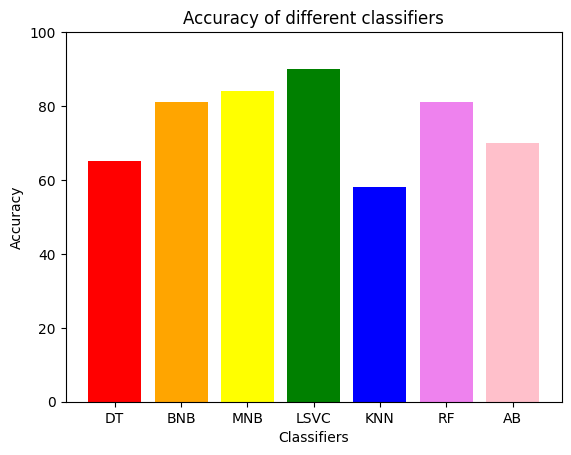

In [2]:
import nltk
from nltk.classify.scikitlearn import SklearnClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from nltk.classify import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
import matplotlib.pyplot as plt
from nltk.corpus import movie_reviews
import random


docs = [(list(movie_reviews.words(fileid)), category)
        for category in movie_reviews.categories()
        for fileid in movie_reviews.fileids(category)]

random.seed(43)
random.shuffle(docs)

all_words = []
for w in movie_reviews.words():
  all_words.append(w.lower())

all_words = nltk.FreqDist(all_words)

word_features = list(all_words.keys())[:3000]

def find_features(document):
  words = set(document)
  features={}
  for w in word_features:
    features[w] = (w in words)
  return features

featuresets = [(find_features(rev),category) for (rev,category) in docs]

training_set = featuresets[:1900]
testing_set = featuresets[1900:]

DT_classifier = DecisionTreeClassifier.train(training_set)
DT_accuracy=nltk.classify.accuracy(DT_classifier, testing_set)*100
print("Decision Tree accuracy percent:",( DT_accuracy))

BNB_classifier = SklearnClassifier(BernoulliNB())
BNB_classifier.train(training_set)
BNB_accuracy=nltk.classify.accuracy(BNB_classifier, testing_set)*100
print("BernoulliNB accuracy percent:",(BNB_accuracy))

MNB_classifier = SklearnClassifier(MultinomialNB())
MNB_classifier.train(training_set)
MNB_accuracy = nltk.classify.accuracy(MNB_classifier, testing_set)*100
print("MultinomialNB accuracy percent:",(MNB_accuracy))

LSVC_classifier = SklearnClassifier(LinearSVC())
LSVC_classifier.train(training_set)
LSVC_accuracy = nltk.classify.accuracy(LSVC_classifier, testing_set)*100
print("SVM accuracy percent:",(LSVC_accuracy))

KNN_classifier = SklearnClassifier(KNeighborsClassifier())
KNN_classifier.train(training_set)
KNN_accuracy = nltk.classify.accuracy(KNN_classifier, testing_set)*100
print("KNN accuracy percent:",(KNN_accuracy))

RF_classifier = SklearnClassifier(RandomForestClassifier())
RF_classifier.train(training_set)
RF_accuracy = nltk.classify.accuracy(RF_classifier, testing_set)*100
print("Random Forest accuracy percent:",(RF_accuracy))

AB_classifier = SklearnClassifier(AdaBoostClassifier())
AB_classifier.train(training_set)
AB_accuracy = nltk.classify.accuracy(AB_classifier, testing_set)*100
print("Ada Boost accuracy percent:",(AB_accuracy))


classifiers = ['DT', 'BNB', 'MNB', 'LSVC', 'KNN', 'RF', 'AB']
accuracies = [DT_accuracy, BNB_accuracy, MNB_accuracy, LSVC_accuracy, KNN_accuracy, RF_accuracy, AB_accuracy]
colors = ['red', 'orange', 'yellow', 'green', 'blue', 'violet', 'pink']
plt.bar(classifiers, accuracies, color=colors)
plt.title("Accuracy of different classifiers")
plt.xlabel("Classifiers")
plt.ylabel("Accuracy")
plt.ylim(0, 100)
plt.show()

LinearSVC постига най-висока точност (90%), следван от MultinomialNB (84%), BernoulliNB и Random Forest (по 81%). Линейните и наивните Бейсови модели се справят добре с високомерни разредени текстови данни. AdaBoost (70%) е по-слаб, а Decision Tree (65%) и KNN (58%) са най-слаби.

Задача 2

In [15]:
import nltk
from nltk.classify.scikitlearn import SklearnClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from nltk.classify import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
import matplotlib.pyplot as plt
from nltk.corpus import nps_chat
import random


docs = []
for fileid in nps_chat.fileids():
    if 'teens' in fileid:
        category = 'teens'
    elif '40s' in fileid:
        category = '40s'
    else:
        continue

    for post in nps_chat.xml_posts(fileid):
        words = post.text.lower().split()
        words = [w for w in words if w.isalpha()]
        docs.append((words, category))


random.seed(43)
random.shuffle(docs)

all_words = [w for words, _ in docs for w in words]
all_words = nltk.FreqDist(all_words)

word_features = list(all_words.keys())[:1500]

def find_features(document):
  words = set(document)
  features={}
  for w in word_features:
    features[w] = (w in words)
  return features

featuresets = [(find_features(words_list),category) for (words_list,category) in docs]

training_set = featuresets[:-1800]
testing_set = featuresets[-1800:]

print(len(docs), len(training_set), len(testing_set))

classifiers = {
    'BNB': SklearnClassifier(BernoulliNB()),
    'MNB': SklearnClassifier(MultinomialNB()),
    'LSVC': SklearnClassifier(LinearSVC()),
    'KNN': SklearnClassifier(KNeighborsClassifier()),
    'RF': SklearnClassifier(RandomForestClassifier(n_estimators=100)),
    'AB': SklearnClassifier(AdaBoostClassifier()),
}

for name, classifier in classifiers.items():
    classifier.train(training_set)
    acc = nltk.classify.accuracy(classifier, testing_set) * 100
    print(f"{name} accuracy percent: {acc:.2f}")


my_chats = ['omg you are so funny lol', "I would like to talk to you for a minute", "Let me settle this meeting", "hey whats up"]
for message in my_chats:
  feats = find_features(message.lower().split())
  print(message, "->", {name: str(classifier.classify(feats)) for name, classifier in classifiers.items()})

4922 3122 1800
BNB accuracy percent: 72.72
MNB accuracy percent: 72.89
LSVC accuracy percent: 71.89
KNN accuracy percent: 66.50
RF accuracy percent: 71.44
AB accuracy percent: 67.56
omg you are so funny lol -> {'BNB': '40s', 'MNB': '40s', 'LSVC': '40s', 'KNN': '40s', 'RF': 'teens', 'AB': '40s'}
I would like to talk to you for a minute -> {'BNB': '40s', 'MNB': '40s', 'LSVC': 'teens', 'KNN': '40s', 'RF': '40s', 'AB': '40s'}
Let me settle this meeting -> {'BNB': 'teens', 'MNB': 'teens', 'LSVC': 'teens', 'KNN': '40s', 'RF': '40s', 'AB': '40s'}
hey whats up -> {'BNB': 'teens', 'MNB': 'teens', 'LSVC': 'teens', 'KNN': '40s', 'RF': 'teens', 'AB': '40s'}


а) При нормално използване на всички думи (включително цифри и специални символи) резултатите бяха:

BNB accuracy percent: 73.73

MNB accuracy percent: 73.80

LSVC accuracy percent: 72.40

KNN accuracy percent: 63.60

RF accuracy percent: 73.00

AB accuracy percent: 66.67

При изключване на тези с цифри и специални символи:

BNB accuracy percent: 71.93

MNB accuracy percent: 71.93

LSVC accuracy percent: 70.00

KNN accuracy percent: 61.87

RF accuracy percent: 70.07

AB accuracy percent: 66.67

По-лошите резултати при изключване на думите с цифри и специални символи имат логично обяснение, тъй като доста често тийнейджърите пишат с такива символи, което би помогнало на модела за правилно разпознаване на такъв текст.

б) **Резултати при 1500 записа в тестовото множество:**

BNB accuracy percent: 71.93

MNB accuracy percent: 71.93

LSVC accuracy percent: 70.00

KNN accuracy percent: 61.87

RF accuracy percent: 70.07

AB accuracy percent: 66.67


**Резултати при 1000 записа в тестовото множество:**

BNB accuracy percent: 72.70

MNB accuracy percent: 72.90

LSVC accuracy percent: 70.30

KNN accuracy percent: 65.80

RF accuracy percent: 70.10

AB accuracy percent: 68.30


**Резултати при 1800 записа в тестовото множество:**

BNB accuracy percent: 72.72

MNB accuracy percent: 72.89

LSVC accuracy percent: 71.89

KNN accuracy percent: 66.50

RF accuracy percent: 70.78

AB accuracy percent: 67.56

Промяната на размера на обучаващото множество влияе слабо: резултатите на Naive Bayes и LinearSVC остават около 70-73%, а KNN и AdaBoost варират най-много. Разликите са в рамките на няколко пункта и нямат ясна тенденция.

Резултати на точността на Random Forest Classifier при:

n_estimators=20 -> 70.11

n_estimators=100 -> 71.61

n_estimators=200 -> 71.06

Увеличаването на n_estimators от 20 на 100 подобрява точността, но при 200 дървета тя дори леко намалява. Това показва, че след определен брой дървета ансамбълът се стабилизира и допълнителните дървета не носят реална полза, а само увеличават времето за обучение.

в) При собствените ми съобщения предсказанията се различават между алгоритмите, защото късите текстове съдържат малко признаци, а стилът на двете възрастови групи в обучителните данни понякога се припокрива.

Задача 3

In [40]:
import nltk
from nltk.classify.scikitlearn import SklearnClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB,BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from nltk.classify import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
import matplotlib.pyplot as plt
from nltk.corpus import brown
import random

categories = ['science_fiction', 'humor', 'mystery']

CHUNK = 200
docs = []
for category in categories:
  for fileid in brown.fileids(category):
    words = [w.lower() for w in brown.words(fileid) if w.isalpha()]
    for i in range(0, len(words) - CHUNK + 1, CHUNK):
      docs.append((words[i:i + CHUNK], category))


random.seed(43)
random.shuffle(docs)

all_words = [w for words, _ in docs for w in words]
all_words = nltk.FreqDist(all_words)

word_features = list(all_words.keys())[:1500]

def find_features(document):
  words = set(document)
  features={}
  for w in word_features:
    features[w] = (w in words)
  return features

featuresets = [(find_features(words_list),category) for (words_list,category) in docs]

split = int(0.8 * len(featuresets))
training_set = featuresets[:split]
testing_set = featuresets[split:]

print(len(docs), len(training_set), len(testing_set))

classifiers = {
    'BNB': SklearnClassifier(BernoulliNB()),
    'MNB': SklearnClassifier(MultinomialNB()),
    'LSVC': SklearnClassifier(LinearSVC()),
    'KNN': SklearnClassifier(KNeighborsClassifier(n_neighbors=3, metric='cosine')),
    'RF': SklearnClassifier(RandomForestClassifier(n_estimators=100)),
    'AB': SklearnClassifier(AdaBoostClassifier()),
}

for name, classifier in classifiers.items():
    classifier.train(training_set)
    acc = nltk.classify.accuracy(classifier, testing_set) * 100
    print(f"{name} accuracy percent: {acc:.2f}")

352 281 71
BNB accuracy percent: 76.06
MNB accuracy percent: 80.28
LSVC accuracy percent: 70.42
KNN accuracy percent: 74.65
RF accuracy percent: 69.01
AB accuracy percent: 69.01


1. **Резултати при 1500 word features:**

BNB accuracy percent: 76.06

MNB accuracy percent: 80.28

LSVC accuracy percent: 70.42

KNN accuracy percent: 45.07

RF accuracy percent: 67.61

AB accuracy percent: 70.42


**Резултати при 500 word features:**

BNB accuracy percent: 74.65

MNB accuracy percent: 76.06

LSVC accuracy percent: 61.97

KNN accuracy percent: 71.83

RF accuracy percent: 69.01

AB accuracy percent: 74.65


**Резултати при 2500 word features:**

BNB accuracy percent: 69.01

MNB accuracy percent: 73.24

LSVC accuracy percent: 74.65

KNN accuracy percent: 61.97

RF accuracy percent: 67.61

AB accuracy percent: 67.61


**Резултати при 4000 word features:**

BNB accuracy percent: 66.20

MNB accuracy percent: 74.65

LSVC accuracy percent: 81.69

KNN accuracy percent: 64.79

RF accuracy percent: 66.20

AB accuracy percent: 64.79


Увеличаването на броя на word features влияе различно на алгоритмите: при Naive Bayes (особено BNB) точността намалява, защото допълнителните редки думи добавят шум, а LinearSVC се подобрява, защото линейният модел се възползва от по-богатото признаково пространство. KNN е най-добър при малко признаци и пада при повече, тъй като във високомерно разредено пространство разстоянията губят смисъл. Random Forest и AdaBoost почти не се променят, а разликите между тях са в рамките на шума.

2. Резултати на KNN Classifier при:

n_neighbors=3 -> 52.11
- metric='euclidean' -> 52.11 (default)
- metric='manhattan' -> 49.30
- metric='cosine' -> 74.65

n_neighbors=5 -> 45.07

n_neighbors=9 -> 50.70

При K=3 сравнението на метриките показва, че косинусовата метрика дава най-добър резултат (74.65%) в сравнение с евклидовата (52.11%) и Манхатъновата (49.30%). Това е така, защото при текст косинусовата мярка сравнява посоката на векторите, а не абсолютното разстояние, което в разредено високомерно пространство е почти еднакво за всички документи. Промяната на броя съседи (K=3, 5, 9) няма ясна тенденция (52.11, 45.07, 50.70), т.е. влиянието му е малко в сравнение с избора на метрика.

3. Резултати на LSVC класификатора при C=0.01 -> 81.69

Резултати на LSVC класификатора при C=0.1 -> 70.42

Резултати на LSVC класификатора при C=1.0 -> 70.42

Резултати на LSVC класификатора при C=10.0 -> 70.42

При C=0.01 LinearSVC постига най-висока точност (81.69%), а при C=0.1, 1.0 и 10.0 тя е една и съща - 70.42%. Малката стойност на C означава по-силна регуляризация и по-широка разделителна ивица, което предпазва от преобучение при голям брой разредени признаци, докато при по-големи C моделът се нагаждa към обучаващите данни и обобщава по-зле. Еднаквият резултат при C >= 0.1 показва, че оттам нататък увеличаването на C не променя границата.